In [ ]:
!pip install brian2
from brian2 import *
import numpy as np

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 25.7 MB/s eta 0:00:00


In [ ]:
duration = 1*second

V_rest = -75*mV
tau = 10*ms

eqs = '''
dv/dt = (-(v-V_rest))/tau : volt (unless refractory)
'''

def run_condition(rate_audio, rate_visual, duration = 1*second, N = 20):
  start_scope()

  neuron = NeuronGroup(N, eqs,
                     threshold='v > -40*mV',
                     reset='v = V_rest',
                     refractory= 5*ms,
                     method='exponential_euler')
  if rate_audio > 0:
    audio_input = PoissonInput(neuron, 'v', 50, rate_audio*Hz, '3 * mV')
  if rate_visual > 0:
    visual_input = PoissonInput(neuron, 'v', 50, rate_visual*Hz, '3 * mV')

  neuron.v = V_rest

  spike_monitor = SpikeMonitor(neuron)
  run(duration)
  return np.mean(spike_monitor.count) / duration

rate_sweep = np.linspace(5,30,10)


V_sweep = np.zeros(len(rate_sweep))
A_sweep = np.zeros(len(rate_sweep))
AV_sweep = np.zeros(len(rate_sweep))

for idx, r in enumerate(rate_sweep):
  A_sweep[idx] = run_condition(0, r)
  V_sweep[idx] = run_condition(r,0)
  AV_sweep[idx] = run_condition(r, r)

print(A_sweep)
print(V_sweep)
print(AV_sweep)

[ 0.    0.    0.3   2.85 10.15 19.8  29.25 37.3  44.55 52.5 ]
[ 0.    0.    0.55  3.35 10.6  19.55 29.95 37.7  45.25 51.7 ]
[ 0.3   8.5  26.6  42.9  57.3  67.95 77.15 85.5  93.15 99.1 ]


In [ ]:
unimodal_sum = A_sweep + V_sweep
enhancement_idx = np.where(unimodal_sum < 5, np.nan, (AV_sweep - unimodal_sum) / unimodal_sum)

WARNING    /tmp/ipykernel_23194/764725059.py:2: RuntimeWarning: divide by zero encountered in divide
  enhancement_idx = np.where(unimodal_sum < 5, np.nan, (AV_sweep - unimodal_sum) / unimodal_sum)
 [py.warnings]
  enhancement_idx = np.where(unimodal_sum < 5, np.nan, (AV_sweep - unimodal_sum) / unimodal_sum)



In [ ]:
print(enhancement_idx)

[        nan         nan         nan  5.91935484  1.76144578  0.72681067
  0.30320946  0.14        0.03730512 -0.04894434]


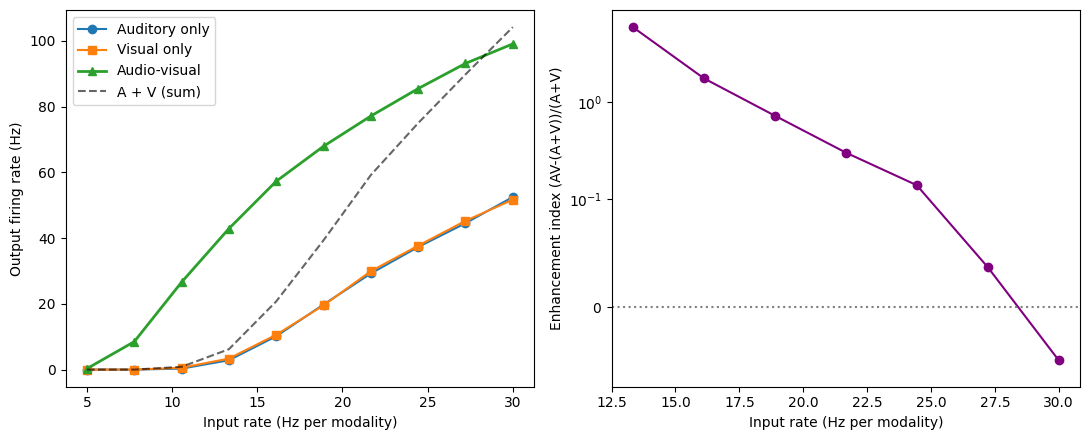

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(rate_sweep, A_sweep, 'o-', label='Auditory only')
ax1.plot(rate_sweep, V_sweep, 's-', label='Visual only')
ax1.plot(rate_sweep, AV_sweep, '^-', label='Audio-visual', linewidth=2)
ax1.plot(rate_sweep, A_sweep + V_sweep, 'k--', label='A + V (sum)', alpha=0.6)
ax1.set_xlabel('Input rate (Hz per modality)')
ax1.set_ylabel('Output firing rate (Hz)')
ax1.legend()

valid = ~np.isnan(enhancement_idx)
ax2.plot(rate_sweep[valid], enhancement_idx[valid], 'o-', color='purple')
ax2.axhline(0, color='gray', linestyle=':')
ax2.set_yscale('symlog', linthresh=0.1)
ax2.set_ylim(bottom=enhancement_idx[valid].min() * 1.5,
             top=enhancement_idx[valid].max() * 1.5)
ax2.set_xlabel('Input rate (Hz per modality)')
ax2.set_ylabel('Enhancement index (AV-(A+V))/(A+V)')

plt.tight_layout()
plt.show()